# Train NAFNet from scratch: your first single-image denoising run

**DSC4008 • Windows + uv + RTX 5060 Ti 16 GB**

Run one cell at a time, from the top. This notebook is self-contained: it reads your downloaded Open Images photographs from disk and does not require variables from your download notebook or a running FiftyOne app.

**Task in this notebook:** RGB photograph + additive Gaussian noise with sigma = 25/255 → original RGB crop. Clean means the source crop before simulated noise; it is not certified noise-free. Inputs are left unclipped; predictions are clipped only for the stated evaluation/display protocol. This is a synthetic-noise pilot, **not a reproduction of the NAFNet SIDD benchmark or Burstormer's camera-noise protocol**. Agree on that shared pipeline before your final comparative experiment.

The model below is a readable implementation of NAFNet's blocks and encoder/decoder architecture using native PyTorch channel LayerNorm. It trains all weights from random initialization. It does not require installing the old BasicSR environment; its checkpoint keys are not guaranteed interchangeable with official checkpoints.

## 0. Install packages in your existing uv project — terminal

Do not run `uv init` again. Keep the project's Python 3.11 environment.

```bash
uv add numpy pillow matplotlib tqdm
uv add "torch==2.7.1" --index pytorch-cu128=https://download.pytorch.org/whl/cu128
uv add --dev ipykernel jupyterlab
uv run jupyter lab
```

This pins a documented CUDA 12.8 PyTorch build rather than claiming it is the newest release. It supports the Blackwell generation used by your RTX 50-series card. Use a sufficiently recent NVIDIA driver. The binary includes its CUDA runtime; this notebook does not compile CUDA extensions. Torchvision and torchaudio are not needed.

If `pyproject.toml` already has a different source for `torch`, replace that source rather than creating conflicting entries. Retain `uv.lock`. Restart your notebook kernel after installation and select the project `.venv` interpreter.

References: [uv/PyTorch](https://docs.astral.sh/uv/guides/integration/pytorch/), [PyTorch 2.7.1 installation matrix](https://pytorch.org/get-started/previous-versions/), [Blackwell support](https://pytorch.org/blog/pytorch-2-7/).

In [1]:
import sys
import torch

print("Python:", sys.version)
print("Interpreter:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.11.15 (main, May 10 2026, 19:31:25) [MSC v.1944 64 bit (AMD64)]
Interpreter: s:\DSC4008-image\.venv\Scripts\python.exe
PyTorch: 2.7.1+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Ti


## 1. Imports and an actual GPU calculation

The CUDA calculation checks more than whether a device name is detected. If it fails, fix the installation/driver before starting a long run. This notebook intentionally requires CUDA for training.

In [2]:
from pathlib import Path
from importlib.metadata import version
from datetime import datetime
import json
import csv
import time
import random
import sys

import numpy as np
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

print("Python:", sys.version.split()[0], sys.executable)
print("PyTorch:", torch.__version__, "CUDA runtime:", torch.version.cuda)
assert torch.cuda.is_available(), "CUDA is unavailable. Check your CUDA-enabled torch installation and NVIDIA driver."
device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))
test = torch.randn(32, 32, device=device)
print("CUDA calculation:", float((test @ test).sum()))
torch.cuda.synchronize()
print("CUDA matrix multiplication passed.")

s:\DSC4008-image\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.11.15 s:\DSC4008-image\.venv\Scripts\python.exe
PyTorch: 2.7.1+cu128 CUDA runtime: 12.8
GPU: NVIDIA GeForce RTX 5060 Ti
CUDA calculation: 277.9060974121094
CUDA matrix multiplication passed.


## 2. Paths and pilot settings

Use your existing downloaded photographs. If your files are somewhere else, edit `DATA_ROOT`. Start at patch size 128 and batch size 2; after checking peak memory, try 256 or batch size 4. Memory use must be measured on your PC.

One epoch below samples 1,000 patches, with replacement, from the available photographs. It does not mean there are 1,000 different source photographs. Ten epochs are an initial pilot, not a promise of convergence. Keep the test split out of this notebook.

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DATA_ROOT = Path("S:/DSC4008-image/data/openimages_v7")
TRAIN_DIR = DATA_ROOT / "zoo" / "open-images-v7" / "train" / "data"
VAL_DIR = DATA_ROOT / "zoo" / "open-images-v7" / "validation" / "data"

config = {
    "seed": SEED,
    "patch_size": 128,
    "batch_size": 2,
    "sigma": 25 / 255.0,
    "patches_per_epoch": 1000,
    "epochs": 10,
    "lr": 1e-3,
    "width": 32,
    "enc_blocks": [2, 2, 4, 8],
    "middle_blocks": 12,
    "dec_blocks": [2, 2, 2, 2],
    "max_train_images": 100,
    "max_val_images": 20,
    "loss": "L1",
    "evaluation": "RGB PSNR, range 1, clip prediction only; unclipped noisy baseline",
}

RESUME = None  # Or Path("S:/DSC4008-image/runs/nafnet_.../last.pt")
RUN_DIR = (RESUME.parent if RESUME is not None else
           DATA_ROOT.parent.parent / "runs" / ("nafnet_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")))
RUN_DIR.mkdir(parents=True, exist_ok=True)
print("Training folder:", TRAIN_DIR)
print("Validation folder:", VAL_DIR)
print("Results:", RUN_DIR)

Training folder: S:\DSC4008-image\data\openimages_v7\zoo\open-images-v7\train\data
Validation folder: S:\DSC4008-image\data\openimages_v7\zoo\open-images-v7\validation\data
Results: S:\DSC4008-image\runs\nafnet_20261028_174147_503428


## 3. Find and check photographs

For this pilot, use at most the counts above. Files are selected in sorted filename order from the cache; **this may differ from the subset shown in your FiftyOne app if the cache has additional images**. The exact paths are saved below. Later you can replace these lists with your frozen group manifests.

The check prevents using a file with the same image ID or identical file bytes across train/validation. It does not detect all near-duplicates. Images too small for a crop are excluded, not upscaled.

In [4]:
import hashlib

def collect_paths(folder, limit):
    if not folder.exists():
        raise FileNotFoundError(f"Folder does not exist: {folder}. Check the filepath printed by your download notebook.")
    candidates = sorted(p for p in folder.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    accepted = []
    for path in candidates:
        try:
            with Image.open(path) as image:
                image.load()
                image = ImageOps.exif_transpose(image)
                if min(image.size) >= config["patch_size"]:
                    accepted.append(path.resolve())
        except OSError:
            continue
        if len(accepted) >= limit:
            break
    if not accepted:
        raise RuntimeError(f"No readable images large enough in {folder}")
    return accepted

train_paths = collect_paths(TRAIN_DIR, config["max_train_images"])
val_paths = collect_paths(VAL_DIR, config["max_val_images"])
assert not ({p.stem for p in train_paths} & {p.stem for p in val_paths}), "Image-ID overlap across splits"
train_hashes = {hashlib.sha256(p.read_bytes()).hexdigest() for p in train_paths}
val_hashes = {hashlib.sha256(p.read_bytes()).hexdigest() for p in val_paths}
assert not train_hashes & val_hashes, "Identical files appear across splits"
print("Usable original photographs:", len(train_paths), "train;", len(val_paths), "validation")

if RESUME is not None:
    assert json.loads((RUN_DIR / "config.json").read_text()) == config, "Config differs from the saved run"
    for split, paths in [("train", train_paths), ("validation", val_paths)]:
        assert (RUN_DIR / f"{split}_files.txt").read_text().splitlines() == [str(p) for p in paths], "Source paths changed"
else:
    (RUN_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
    for split, paths in [("train", train_paths), ("validation", val_paths)]:
        (RUN_DIR / f"{split}_files.txt").write_text("\n".join(str(p) for p in paths) + "\n", encoding="utf-8")

Usable original photographs: 100 train; 20 validation


## 4. Dataset: crop → add noise → convert to a tensor

NumPy uses `(height, width, channels)`. PyTorch expects `(channels, height, width)`. Training generates new noise and crops each time. Validation creates the same pair for a given image index using a fixed seed.

`num_workers=0` in the next cell is intentional for Windows notebook compatibility. It avoids multiprocessing problems with classes defined inside notebook cells.

In [6]:
class DenoisingDataset(Dataset):
    def __init__(self, paths, patch_size, sigma, seed, training, length=None):
        self.paths = list(paths)
        self.patch_size = patch_size
        self.sigma = sigma
        self.seed = seed
        self.training = training
        self.length = length if training and length is not None else len(self.paths)
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return self.length

    def __getitem__(self, index):
        rng = self.rng if self.training else np.random.default_rng(self.seed + index)
        path = self.paths[int(rng.integers(len(self.paths)))] if self.training else self.paths[index]
        with Image.open(path) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            image = np.asarray(image, dtype=np.float32) / 255.0
        h, w, _ = image.shape
        p = self.patch_size
        top = int(rng.integers(h - p + 1))
        left = int(rng.integers(w - p + 1))
        clean = image[top:top+p, left:left+p].copy()
        if self.training:
            if rng.random() < 0.5:
                clean = clean[:, ::-1]
            if rng.random() < 0.5:
                clean = clean[::-1]
        noise = rng.normal(0, self.sigma, clean.shape).astype(np.float32)
        noisy = clean + noise
        def tensor(array):
            return torch.from_numpy(np.ascontiguousarray(array.transpose(2, 0, 1)))
        return tensor(noisy), tensor(clean)

train_data = DenoisingDataset(train_paths, config["patch_size"], config["sigma"], SEED, True, config["patches_per_epoch"])
val_data = DenoisingDataset(val_paths, config["patch_size"], config["sigma"], SEED + 10000, False)
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_data, batch_size=config["batch_size"], shuffle=False,
                          num_workers=0, pin_memory=True, generator=loader_generator)
val_loader = DataLoader(val_data, batch_size=1, shuffle=False, num_workers=0, generator=loader_generator)
# shuffle=False is deliberate: training chooses a random source in __getitem__.
noisy_example, clean_example = val_data[0]
assert torch.equal(val_data[0][0], noisy_example), "Validation noise should be fixed"
print("One input:", noisy_example.shape, noisy_example.dtype)
print("Batches per training epoch:", len(train_loader))

One input: torch.Size([3, 128, 128]) torch.float32
Batches per training epoch: 500


## 5. NAFNet architecture

NAF blocks use channel normalization, depthwise convolution, SimpleGate, simplified channel attention, and two learned residual scales initialized to zero. The encoder reduces spatial size; the decoder restores it using skip connections. A final residual adds the noisy input internally. **Do not add the input again outside the model.**

This native-PyTorch implementation follows the architecture in [Simple Baselines for Image Restoration](https://arxiv.org/abs/2204.04676) and the [official NAFNet architecture](https://github.com/megvii-research/NAFNet/blob/main/basicsr/models/archs/NAFNet_arch.py). Channel LayerNorm uses `nn.LayerNorm` with permuted axes rather than the repository's custom autograd class. It is not a benchmark-equivalence or checkpoint-compatibility claim.

In [7]:
class ChannelLayerNorm(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.norm = nn.LayerNorm(channels, eps=1e-6)

    def forward(self, x):
        return self.norm(x.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)


class SimpleGate(nn.Module):
    def forward(self, x):
        a, b = x.chunk(2, dim=1)
        return a * b


class NAFBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.norm1 = ChannelLayerNorm(channels)
        self.expand1 = nn.Conv2d(channels, 2 * channels, 1)
        self.depthwise = nn.Conv2d(2 * channels, 2 * channels, 3, padding=1, groups=2 * channels)
        self.gate1 = SimpleGate()
        self.attention = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(channels, channels, 1))
        self.project1 = nn.Conv2d(channels, channels, 1)
        self.norm2 = ChannelLayerNorm(channels)
        self.expand2 = nn.Conv2d(channels, 2 * channels, 1)
        self.gate2 = SimpleGate()
        self.project2 = nn.Conv2d(channels, channels, 1)
        self.beta = nn.Parameter(torch.zeros(1, channels, 1, 1))
        self.gamma = nn.Parameter(torch.zeros(1, channels, 1, 1))

    def forward(self, x):
        a = self.gate1(self.depthwise(self.expand1(self.norm1(x))))
        y = x + self.beta * self.project1(a * self.attention(a))
        b = self.project2(self.gate2(self.expand2(self.norm2(y))))
        return y + self.gamma * b


class NAFNet(nn.Module):
    def __init__(self, width=32, enc_blocks=(2, 2, 4, 8), middle_blocks=12, dec_blocks=(2, 2, 2, 2)):
        super().__init__()
        assert len(enc_blocks) == len(dec_blocks)
        self.input_conv = nn.Conv2d(3, width, 3, padding=1)
        self.output_conv = nn.Conv2d(width, 3, 3, padding=1)
        self.encoders, self.downs = nn.ModuleList(), nn.ModuleList()
        self.decoders, self.ups = nn.ModuleList(), nn.ModuleList()
        channels = width
        for blocks in enc_blocks:
            self.encoders.append(nn.Sequential(*[NAFBlock(channels) for _ in range(blocks)]))
            self.downs.append(nn.Conv2d(channels, 2 * channels, 2, stride=2))
            channels *= 2
        self.middle = nn.Sequential(*[NAFBlock(channels) for _ in range(middle_blocks)])
        for blocks in dec_blocks:
            self.ups.append(nn.Sequential(nn.Conv2d(channels, 2 * channels, 1, bias=False), nn.PixelShuffle(2)))
            channels //= 2
            self.decoders.append(nn.Sequential(*[NAFBlock(channels) for _ in range(blocks)]))
        self.multiple = 2 ** len(enc_blocks)

    def forward(self, image):
        h, w = image.shape[-2:]
        padded = F.pad(image, (0, (-w) % self.multiple, 0, (-h) % self.multiple))
        x = self.input_conv(padded)
        skips = []
        for encoder, down in zip(self.encoders, self.downs):
            x = encoder(x)
            skips.append(x)
            x = down(x)
        x = self.middle(x)
        for up, decoder, skip in zip(self.ups, self.decoders, reversed(skips)):
            x = decoder(up(x) + skip)
        restored = self.output_conv(x) + padded
        return restored[..., :h, :w]


def new_model():
    return NAFNet(width=config["width"], enc_blocks=config["enc_blocks"],
                  middle_blocks=config["middle_blocks"], dec_blocks=config["dec_blocks"]).to(device)

model = new_model()
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
with torch.no_grad():
    output = model(noisy_example.unsqueeze(0).to(device))
assert output.shape == (1, 3, config["patch_size"], config["patch_size"])
print("Forward pass:", output.shape)
del output

Trainable parameters: 29,159,715
Forward pass: torch.Size([1, 3, 128, 128])


## 6. Loss, optimizer, and validation

L1 measures mean absolute pixel error. AdamW updates **all** model parameters. This pilot uses full precision for easier debugging.

PSNR is calculated per RGB image at range 1, then averaged. We report both raw model predictions and clipped predictions so the clipping convention is visible. The noisy baseline is unclipped. Comparisons must use a consistent protocol. Higher PSNR is better. Validation here is one fixed patch per image, not a full-image benchmark.

In [8]:
criterion = nn.L1Loss()
optimizer = torch.optim.AdamW(model.parameters(), lr=config["lr"], betas=(0.9, 0.9), weight_decay=0.0)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config["epochs"], eta_min=1e-6)

def image_psnr(prediction, target):
    mse = (prediction.float() - target.float()).square().mean(dim=(1, 2, 3))
    return -10 * torch.log10(mse.clamp_min(1e-12))

@torch.no_grad()
def evaluate(net):
    net.eval()
    stats = {"val_l1": [], "noisy_psnr": [], "raw_psnr": [], "clipped_psnr": []}
    for noisy, clean in val_loader:
        noisy, clean = noisy.to(device), clean.to(device)
        prediction = net(noisy)
        stats["val_l1"].append(float(criterion(prediction, clean)))
        stats["noisy_psnr"].extend(image_psnr(noisy, clean).cpu().tolist())
        stats["raw_psnr"].extend(image_psnr(prediction, clean).cpu().tolist())
        stats["clipped_psnr"].extend(image_psnr(prediction.clamp(0, 1), clean).cpu().tolist())
    return {key: float(np.mean(values)) for key, values in stats.items()}

print("Before training:", evaluate(model))

Before training: {'val_l1': 0.18402303494513034, 'noisy_psnr': 20.17363109588623, 'raw_psnr': 13.151103925704955, 'clipped_psnr': 14.924819374084473}


## 7. Train and save checkpoints

Start this cell only after the earlier cells pass. It runs the pilot and validates every epoch. `best.pt` is chosen using **raw validation PSNR**. `last.pt` is written after every completed epoch. Interrupting mid-epoch loses only that epoch's unsaved progress; it does not save a partial-epoch checkpoint.

To continue an interrupted run, set `RESUME` in Step 2 to its `last.pt`, then run from the top with the **same config**. Resume restores epoch-boundary model, optimizer, scheduler, and random states. For an extended/new schedule, begin a new documented run rather than editing resume settings silently.

On CUDA out-of-memory, reduce batch size, restart the kernel, and rerun from the top. If necessary reduce patch size. The first run only uses 100 training source images; it is a pipeline experiment.

In [9]:
start_epoch = 0
best_psnr = -float("inf")
history = []
global_step = 0

if RESUME is not None:
    checkpoint = torch.load(RESUME, map_location="cpu", weights_only=True)
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value) and key != "step":
                state[key] = value.to(device)
    scheduler.load_state_dict(checkpoint["scheduler"])
    start_epoch = checkpoint["epoch"] + 1
    best_psnr = checkpoint["best_psnr"]
    history = checkpoint["history"]
    global_step = checkpoint["global_step"]
    train_data.rng.bit_generator.state = checkpoint["data_rng"]
    loader_generator.set_state(checkpoint["loader_rng"])
    torch.set_rng_state(checkpoint["torch_rng"])
    torch.cuda.set_rng_state_all(checkpoint["cuda_rng"])
    print("Resuming at epoch", start_epoch + 1)

def save_checkpoint(path, epoch):
    state = {
        "model": model.state_dict(), "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(), "config": config,
        "epoch": epoch, "global_step": global_step, "best_psnr": best_psnr,
        "history": history, "data_rng": train_data.rng.bit_generator.state,
        "loader_rng": loader_generator.get_state(), "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state_all(),
    }
    temporary = path.with_suffix(".tmp")
    torch.save(state, temporary)
    temporary.replace(path)

for epoch in range(start_epoch, config["epochs"]):
    model.train()
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    started = time.perf_counter()
    loss_sum, samples = 0.0, 0
    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{config['epochs']}")
    for noisy, clean in progress:
        noisy = noisy.to(device, non_blocking=True)
        clean = clean.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        prediction = model(noisy)
        loss = criterion(prediction, clean)
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss; stop and inspect the inputs and model")
        loss.backward()
        optimizer.step()
        batch_count = noisy.shape[0]
        loss_sum += loss.item() * batch_count
        samples += batch_count
        global_step += 1
        progress.set_postfix(l1=f"{loss_sum / samples:.5f}")
    lr_used = optimizer.param_groups[0]["lr"]
    scheduler.step()
    metrics = evaluate(model)
    torch.cuda.synchronize()
    row = {"epoch": epoch + 1, "step": global_step, "train_l1": loss_sum / samples,
           "lr": lr_used, "seconds": time.perf_counter() - started,
           "peak_allocated_GiB": torch.cuda.max_memory_allocated() / 1024**3, **metrics}
    history.append(row)
    improved = metrics["raw_psnr"] > best_psnr
    best_psnr = max(best_psnr, metrics["raw_psnr"])
    with (RUN_DIR / "history.csv").open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)
    save_checkpoint(RUN_DIR / "last.pt", epoch)
    if improved:
        save_checkpoint(RUN_DIR / "best.pt", epoch)
    print({key: round(value, 5) if isinstance(value, float) else value for key, value in row.items()})

print("Best raw validation PSNR:", best_psnr)
print("Checkpoints and logs:", RUN_DIR)

Epoch 1/10: 100%|██████████| 500/500 [00:59<00:00,  8.41it/s, l1=0.02946]


{'epoch': 1, 'step': 500, 'train_l1': 0.02946, 'lr': 0.001, 'seconds': 60.28777, 'peak_allocated_GiB': 0.91845, 'val_l1': 0.01944, 'noisy_psnr': 20.17363, 'raw_psnr': 31.70567, 'clipped_psnr': 31.76951}


Epoch 2/10: 100%|██████████| 500/500 [00:56<00:00,  8.85it/s, l1=0.01891]


{'epoch': 2, 'step': 1000, 'train_l1': 0.01891, 'lr': 0.00098, 'seconds': 57.23802, 'peak_allocated_GiB': 0.91845, 'val_l1': 0.01779, 'noisy_psnr': 20.17363, 'raw_psnr': 32.53355, 'clipped_psnr': 32.59887}


Epoch 3/10: 100%|██████████| 500/500 [00:58<00:00,  8.56it/s, l1=0.01732]


...

{'epoch': 8, 'step': 4000, 'train_l1': 0.01581, 'lr': 0.00021, 'seconds': 58.74877, 'peak_allocated_GiB': 0.91845, 'val_l1': 0.01543, 'noisy_psnr': 20.17363, 'raw_psnr': 33.74239, 'clipped_psnr': 33.76563}


Epoch 9/10: 100%|██████████| 500/500 [00:57<00:00,  8.74it/s, l1=0.01539]


{'epoch': 9, 'step': 4500, 'train_l1': 0.01539, 'lr': 0.0001, 'seconds': 58.00487, 'peak_allocated_GiB': 0.91845, 'val_l1': 0.01531, 'noisy_psnr': 20.17363, 'raw_psnr': 33.81343, 'clipped_psnr': 33.83769}


Epoch 10/10: 100%|██████████| 500/500 [00:56<00:00,  8.82it/s, l1=0.01555]


{'epoch': 10, 'step': 5000, 'train_l1': 0.01555, 'lr': 3e-05, 'seconds': 57.46127, 'peak_allocated_GiB': 0.91845, 'val_l1': 0.01524, 'noisy_psnr': 20.17363, 'raw_psnr': 33.84566, 'clipped_psnr': 33.86833}
Best raw validation PSNR: 33.84566078186035
Checkpoints and logs: S:\DSC4008-image\runs\nafnet_20261028_174147_503428


## 8. Reload the best checkpoint and inspect a result

This uses the same validation patch as before training. It does not use the held-out test set. Visual examples help reveal oversmoothing that a single score can hide.

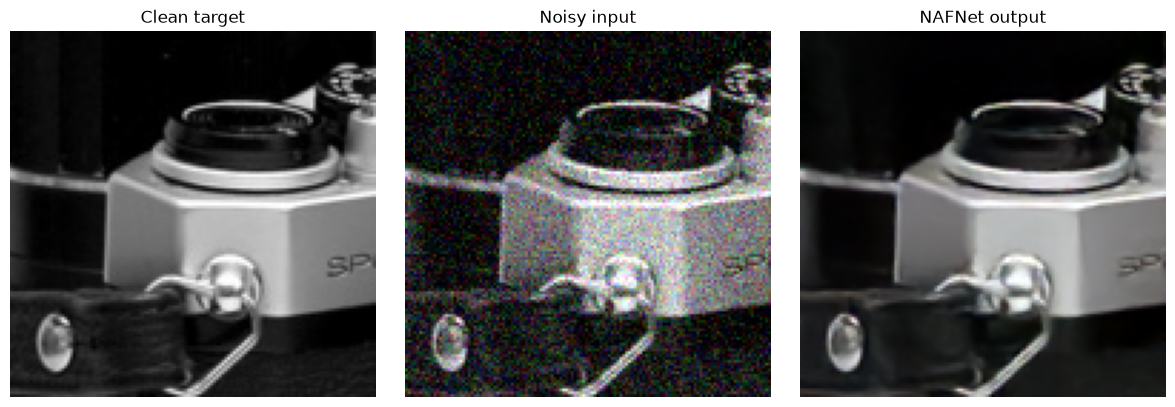

Best checkpoint validation: {'val_l1': 0.015239791572093963, 'noisy_psnr': 20.17363109588623, 'raw_psnr': 33.84566078186035, 'clipped_psnr': 33.86833248138428}


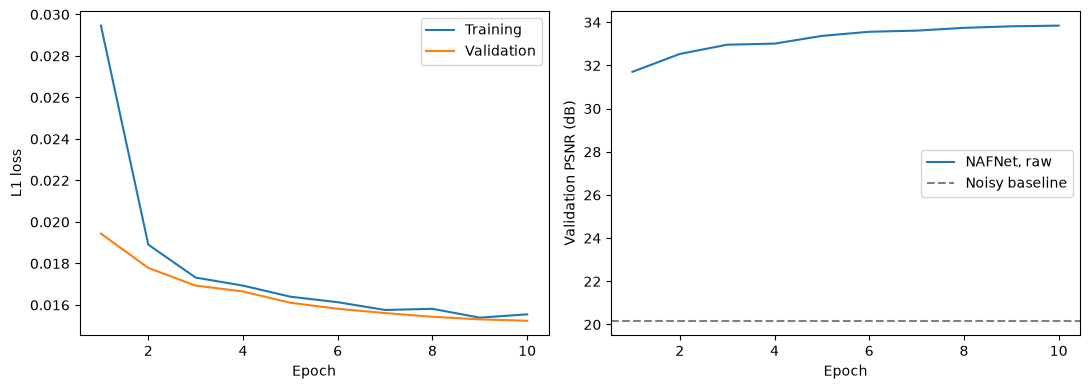

In [19]:
best = torch.load(RUN_DIR / "best.pt", map_location="cpu", weights_only=True)
model.load_state_dict(best["model"])
model.eval()
noisy, clean = val_data[9]
with torch.no_grad():
    restored = model(noisy.unsqueeze(0).to(device)).cpu()[0]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, tensor, title in zip(axes, [clean, noisy, restored], ["Clean target", "Noisy input", "NAFNet output"]):
    ax.imshow(tensor.permute(1, 2, 0).clamp(0, 1).numpy())
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Best checkpoint validation:", evaluate(model))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot([r["epoch"] for r in history], [r["train_l1"] for r in history], label="Training")
axes[0].plot([r["epoch"] for r in history], [r["val_l1"] for r in history], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="L1 loss")
axes[0].legend()
axes[1].plot([r["epoch"] for r in history], [r["raw_psnr"] for r in history], label="NAFNet, raw")
axes[1].axhline(history[0]["noisy_psnr"], linestyle="--", color="gray", label="Noisy baseline")
axes[1].set(xlabel="Epoch", ylabel="Validation PSNR (dB)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 9. What to do with the pilot result

- A useful first result has finite, generally decreasing training loss and validation PSNR above the noisy-input baseline. Randomly initialized output can initially be worse than the noisy input.
- If it cannot learn, first check the model can overfit a few **fixed** noisy/clean pairs. Do not repeatedly tune against test images.
- Once stable, use your frozen 5,000/500 source-image lists, increase patch size to 256 if memory allows, and train longer based on validation progress. Source count alone does not determine the necessary step budget.
- Tune one setting at a time. The initial LR, duration, patch size, loss, and batch size are pilot choices, not published optimal settings.
- Full-image inference is a separate validation task. This notebook reports fixed-patch validation only; do not call those numbers SIDD or Burstormer benchmark results.
- For the final shared project, replace this Gaussian generator with your agreed burst generator. NAFNet takes its reference frame. Both models must use the same clean target, output space, and evaluation protocol.

**Files you produced:** `config.json`, exact source-file lists, `history.csv`, `last.pt`, and `best.pt`. Back up the run folder and your uv lockfile.

**Verification of this supplied notebook:** Python syntax and notebook structure checked. The execution environment used to prepare it has no PyTorch or NVIDIA GPU, so model execution, CUDA compatibility, memory usage, and convergence have not been measured here. The GPU, shape, and validation cells are provided to check these on your PC.